# 03 · Trading simulation, profitability vs benchmarks, deep analysis

Costs: 15 bps per side (30 bps round trip). Capital $10,000. TEST window 2024-01-01 → today.


In [1]:
import sys, warnings, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3})
from driftrev import config, store, artifacts, dataset, features, models, simulate, analysis, pipeline
print("data dir:", config.DATA_DIR)

data dir: /Users/mac/Documents/New project/stock-data-analysis/project/data


In [2]:
metrics = artifacts.load_metrics()
trades, eq = artifacts.load_frame("trades"), artifacts.load_frame("equity")

### Vector simulations (`sim1_` hold-to-horizon, `sim2_` with stop-loss / take-profit)

In [3]:
artifacts.load_frame("vector_sims.parquet").head(20).round(4)

,prediction,sim,n_trades,avg_trades_per_day,q75_trades_per_day,gross,fees,net,capital,cagr,hit_rate,avg_net_return
0,pred9_ensemble_top1_daily,sim1,423,1.0000,1.00,1369.1066,126.9,1242.2066,1000.0,0.3308,0.5603,0.0294
1,pred8_ensemble_best_rule_47,sim1,7204,17.0307,21.00,12876.6372,2161.2,10715.4372,21000.0,0.1571,0.5641,0.0149
2,pred3_lgbm_best_rule_49,sim1,6649,15.6080,20.00,11507.3897,1994.7,9512.6897,20000.0,0.1476,0.5527,0.0143
3,pred7_xgb_best_rule_48,sim1,11260,23.3126,30.00,16466.6740,3378.0,13088.6740,30000.0,0.1367,0.5510,0.0116
4,pred9_ensemble_top1_daily,sim2_sl_tp,423,1.0000,1.00,543.8600,126.9,416.9600,1000.0,0.1313,0.5603,0.0099
5,pred8_ensemble_best_rule_47,sim2_sl_tp,7204,17.0307,21.00,10078.7974,2161.2,7917.5974,21000.0,0.1199,0.5641,0.0110
6,pred1_manual_panic_no_damage,sim1,1587,3.5905,4.00,1817.2988,476.1,1341.1988,4000.0,0.1078,0.5457,0.0085
7,pred3_lgbm_best_rule_49,sim2_sl_tp,6649,15.6080,20.00,8619.0439,1994.7,6624.3439,20000.0,0.1066,0.5527,0.0100
8,pred7_xgb_best_rule_48,sim2_sl_tp,11260,23.3126,30.00,13195.2641,3378.0,9817.2641,30000.0,0.1054,0.5510,0.0087
9,pred1_manual_panic_no_damage,sim2_sl_tp,1587,3.5905,4.00,1604.2478,476.1,1128.1478,4000.0,0.0919,0.5457,0.0071


### Exact simulations (daily loop, reinvestment, max concurrent positions) vs benchmarks

In [4]:
res = pd.DataFrame(metrics["strategies"] + metrics["benchmarks"])
res[["name", "cagr", "sharpe", "sortino", "max_drawdown", "calmar", "rolling_1y_median", "n_trades", "win_rate", "final_equity"]].sort_values("cagr", ascending=False).round(3)

,name,cagr,sharpe,sortino,max_drawdown,calmar,rolling_1y_median,n_trades,win_rate,final_equity
0,all_events_unconditional,0.406,1.029,1.644,-0.496,0.819,0.487,360.0,0.525,26541.231
5,model_crash_only,0.375,1.579,1.437,-0.097,3.861,0.522,54.0,0.704,24883.878
1,model_top5,0.352,1.276,1.410,-0.149,2.361,0.481,92.0,0.587,23739.289
15,hw1_momentum_top_quintile,0.230,1.050,1.458,-0.241,0.955,0.212,NaN,NaN,18082.590
3,model_top5_risk_managed,0.195,1.390,1.394,-0.109,1.785,0.229,100.0,0.590,16661.924
13,SPY_buy_hold,0.191,1.194,1.558,-0.188,1.016,0.174,NaN,NaN,16482.196
2,model_top3_concentrated,0.147,0.638,0.569,-0.238,0.619,0.076,58.0,0.552,14828.178
14,IWM_buy_hold,0.134,0.706,1.077,-0.275,0.487,0.148,NaN,NaN,14329.602
7,model_long_short,0.099,0.654,1.004,-0.195,0.511,0.103,324.0,0.497,13118.643
4,model_pead_only,0.092,0.671,0.494,-0.166,0.552,0.051,52.0,0.635,12856.500


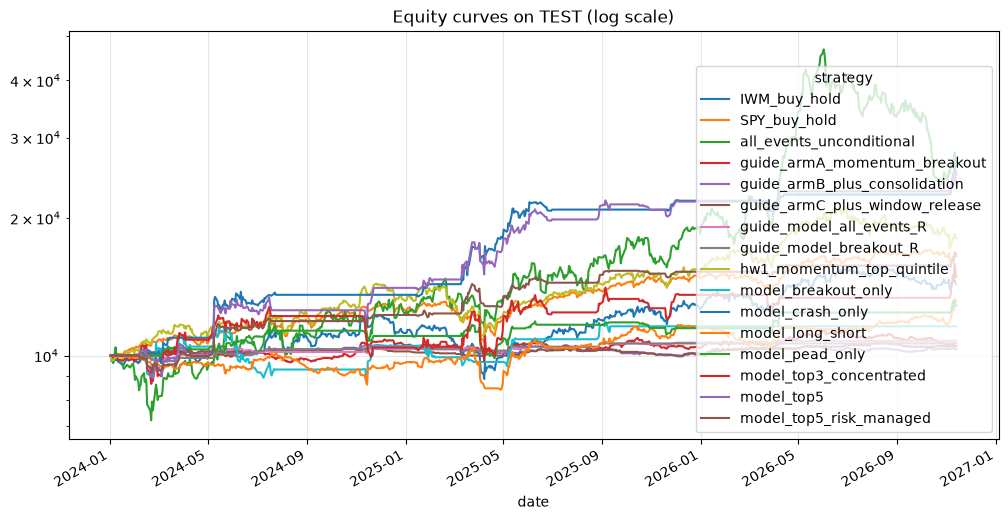

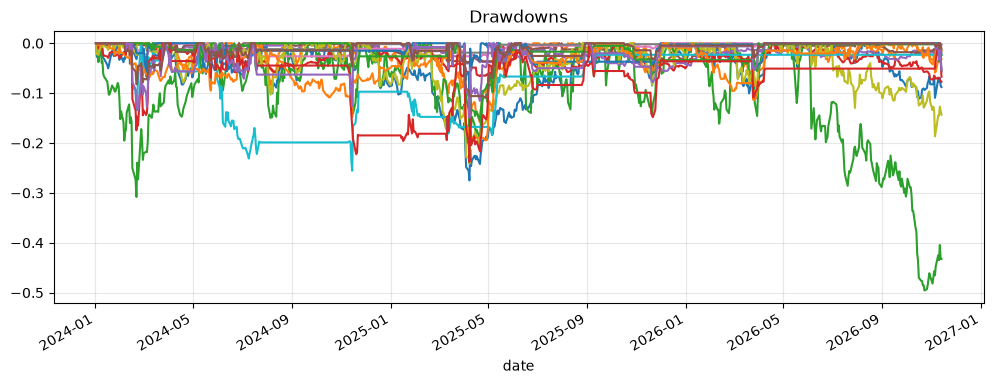

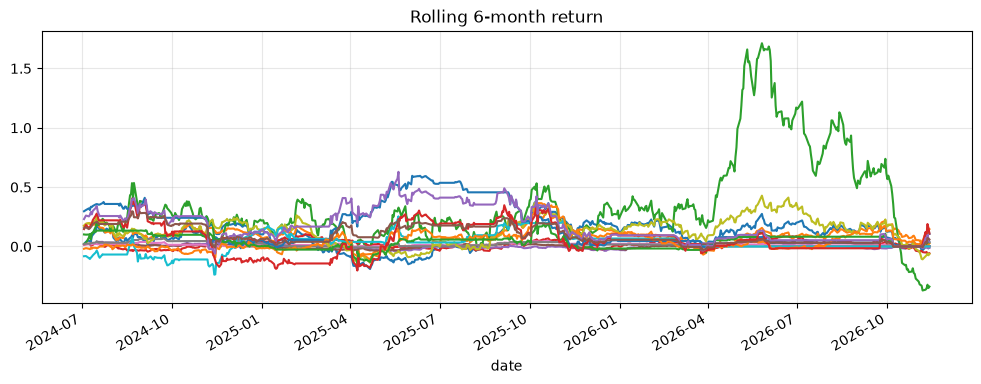

In [5]:
w = eq.pivot_table(index="date", columns="strategy", values="equity").ffill()
w.plot(logy=True, figsize=(12, 6), title="Equity curves on TEST (log scale)"); plt.show()
(w / w.cummax() - 1).plot(figsize=(12, 4), title="Drawdowns", legend=False); plt.show()
w.pct_change(126).plot(figsize=(12, 4), title="Rolling 6-month return", legend=False); plt.show()

### Trade anatomy of the best strategy

In [6]:
best = metrics.get("best_strategy"); print("best strategy:", best)
t = trades[trades.strategy == best]
display(t.groupby("exit_reason").agg(n=("pnl", "size"), avg_ret=("ret_net", "mean"), pnl=("pnl", "sum")).round(4))
display(t.groupby("event_family").agg(n=("pnl", "size"), win=("pnl", lambda s: (s > 0).mean()), avg_ret=("ret_net", "mean")).round(4))
t.sort_values("pnl").head(10)

best strategy: all_events_unconditional


,n,avg_ret,pnl
exit_reason,,,
time,360,0.0181,16541.2314


,n,win,avg_ret
event_family,,,
earnings_crash,49,0.4694,0.0002
earnings_down,34,0.5882,0.0349
earnings_up,53,0.6792,0.0313
momentum_breakout,194,0.4897,0.0095
shock_crash,30,0.5000,0.0611


,strategy,ticker,side,event_family,event_date,prob,entry_date,entry_price,exit_date,exit_price,ret_net,pnl,exit_reason,days_held,notional,r_multiple
347,all_events_unconditional,COHR,long,momentum_breakout,2026-10-02,0.418544,2026-10-05,340.929993,2026-10-16,232.899994,-0.319393,-2175.663883,time,10,6811.865235,NaN
316,all_events_unconditional,PENG,long,momentum_breakout,2026-07-09,0.437902,2026-07-10,78.879997,2026-07-23,58.410000,-0.262119,-2048.013094,time,10,7813.300222,NaN
348,all_events_unconditional,AOSL,long,momentum_breakout,2026-10-02,0.417399,2026-10-05,29.840000,2026-10-16,21.750000,-0.273706,-1864.447946,time,10,6811.865235,NaN
349,all_events_unconditional,ACLS,long,momentum_breakout,2026-10-02,0.416108,2026-10-05,147.770004,2026-10-16,108.349998,-0.269366,-1821.142531,time,10,6760.852764,NaN
319,all_events_unconditional,SRPT,long,momentum_breakout,2026-07-09,0.423034,2026-07-10,20.540001,2026-07-23,15.880000,-0.229534,-1779.988406,time,10,7754.788238,NaN
346,all_events_unconditional,AMKR,long,momentum_breakout,2026-10-02,0.418587,2026-10-05,56.060001,2026-10-16,41.820000,-0.256633,-1748.146415,time,10,6811.865235,NaN
345,all_events_unconditional,VECO,long,momentum_breakout,2026-10-02,0.421225,2026-10-05,56.410000,2026-10-16,42.750000,-0.244792,-1667.492912,time,10,6811.865235,NaN
300,all_events_unconditional,SEDG,long,momentum_breakout,2026-05-26,0.442657,2026-05-27,70.224998,2026-06-09,57.799999,-0.179666,-1519.987155,time,10,8460.076476,NaN
327,all_events_unconditional,UTI,long,earnings_crash,2026-08-06,0.430321,2026-08-07,28.000000,2026-08-20,22.920000,-0.184156,-1419.781500,time,10,7709.649520,NaN
302,all_events_unconditional,VICR,long,momentum_breakout,2026-05-26,0.441335,2026-05-27,338.600006,2026-06-09,283.480011,-0.165544,-1400.512795,time,10,8460.076476,NaN


### Where does the model work? Precision by event type, cause, sector, size, year, regime

In [7]:
bd = artifacts.load_frame("breakdown")
for dim in ["event_family", "edgar_category", "cap_bucket", "year", "regime_state", "sector", "prob_bucket"]:
    display(bd[bd.dimension == dim].sort_values("n", ascending=False).round(3))

,dimension,value,n,base_rate,n_selected,precision,avg_growth,avg_growth_all,lift
3,event_family,momentum_breakout,27252,0.395,399,0.363,0.992,1.007,-0.032
2,event_family,earnings_up,8952,0.400,255,0.584,1.032,1.006,0.184
1,event_family,earnings_down,7244,0.398,208,0.587,1.038,1.007,0.188
0,event_family,earnings_crash,1412,0.429,82,0.512,1.047,1.008,0.083
4,event_family,shock_crash,891,0.473,48,0.625,1.069,1.026,0.152


,dimension,value,n,base_rate,n_selected,precision,avg_growth,avg_growth_all,lift
10,edgar_category,none,25365,0.398,381,0.381,0.999,1.007,-0.017
7,edgar_category,earnings,17960,0.402,552,0.576,1.036,1.006,0.174
11,edgar_category,offering,840,0.390,22,0.455,1.007,1.009,0.064
12,edgar_category,regfd_other_8k,826,0.393,18,0.500,1.040,1.008,0.107
9,edgar_category,mgmt_change,413,0.414,12,0.083,0.954,1.007,-0.331
6,edgar_category,deal,268,0.340,4,0.750,1.026,0.996,0.410
13,edgar_category,restatement_auditor,53,0.453,3,0.667,1.126,1.006,0.214
5,edgar_category,bankruptcy_delisting,17,0.353,0,NaN,NaN,1.000,NaN
8,edgar_category,impairment_restructuring,9,0.333,0,NaN,NaN,0.994,NaN


,dimension,value,n,base_rate,n_selected,precision,avg_growth,avg_growth_all,lift
27,cap_bucket,small,17226,0.396,471,0.452,1.013,1.005,0.057
25,cap_bucket,large,15823,0.405,234,0.543,1.034,1.010,0.137
26,cap_bucket,mid,12702,0.397,287,0.516,1.022,1.006,0.119


,dimension,value,n,base_rate,n_selected,precision,avg_growth,avg_growth_all,lift
29,year,2025,15881,0.394,580,0.588,1.040,1.006,0.194
28,year,2024,15567,0.397,400,0.342,0.991,1.008,-0.055
30,year,2026,14303,0.408,12,0.833,1.074,1.007,0.426


,dimension,value,n,base_rate,n_selected,precision,avg_growth,avg_growth_all,lift
44,regime_state,normal,42490,0.390,424,0.354,0.993,1.005,-0.036
43,regime_state,elevated,2365,0.512,542,0.590,1.040,1.034,0.078
45,regime_state,stressed,896,0.562,26,0.692,1.056,1.035,0.130


,dimension,value,n,base_rate,n_selected,precision,avg_growth,avg_growth_all,lift
21,sector,Information Technology,8256,0.440,245,0.498,1.016,1.012,0.058
20,sector,Industrials,7876,0.407,135,0.504,1.031,1.009,0.097
15,sector,Consumer Discretionary,6177,0.381,167,0.587,1.035,1.001,0.206
18,sector,Financials,5878,0.402,59,0.441,1.028,1.009,0.039
19,sector,Health Care,5599,0.394,178,0.399,1.003,1.006,0.005
17,sector,Energy,2973,0.411,51,0.549,1.032,1.005,0.138
22,sector,Materials,2194,0.395,49,0.531,1.032,1.004,0.136
16,sector,Consumer Staples,1939,0.362,35,0.514,1.014,1.004,0.153
23,sector,Real Estate,1861,0.333,26,0.385,1.007,1.002,0.051
14,sector,Communication Services,1585,0.375,39,0.359,0.992,1.004,-0.016


,dimension,value,n,base_rate,n_selected,precision,avg_growth,avg_growth_all,lift
69,prob_bucket,"(0.0, 0.4]",28715,0.378,0,NaN,NaN,1.003,NaN
70,prob_bucket,"(0.4, 0.5]",16804,0.433,760,0.475,1.017,1.013,0.042
71,prob_bucket,"(0.5, 0.55]",232,0.547,232,0.547,1.031,1.031,0.000


### Debugging the most confident wrong predictions

In [8]:
artifacts.load_frame("false_positives.parquet")

,date,ticker,company,event_family,edgar_category,edgar_items,proba_rf,abn_ret_1d,growth_future_10d,mae_10d,regime_state,sector
0,2025-05-06,IQV,IQVIA,earnings_down,earnings,2.02,0.543171,-0.031914,0.968917,-0.081952,elevated,Health Care
1,2025-05-08,HP,"Helmerich & Payne, Inc.",earnings_down,earnings,2.02,0.538547,-0.044264,0.841142,-0.211093,elevated,Energy
2,2025-05-08,VIR,"Vir Biotechnology, Inc.",earnings_down,earnings,"2.02,8.01",0.536582,-0.045191,0.852126,-0.201479,elevated,Health Care
3,2025-05-09,PDFS,"PDF Solutions, Inc.",earnings_down,earnings,2.02,0.536478,-0.058631,0.955232,-0.052577,elevated,Information Technology
4,2025-05-06,XNCR,Xencor Inc,shock_crash,none,,0.536300,-0.199877,0.950935,-0.082944,elevated,Health Care
5,2025-05-06,SRPT,Sarepta Therapeutics,shock_crash,earnings,,0.534902,-0.256326,1.000000,-0.147287,elevated,Health Care
6,2025-05-08,CLF,Cleveland-Cliffs,earnings_crash,earnings,2.02,0.531031,-0.169428,0.968056,-0.054167,elevated,Materials
7,2025-05-06,ENR,Energizer,earnings_down,earnings,2.02,0.530225,-0.074321,0.997904,-0.098952,elevated,Consumer Staples
8,2025-05-08,XNCR,Xencor Inc,earnings_up,earnings,"2.02,5.02",0.528020,0.091634,0.869909,-0.178733,elevated,Health Care
9,2025-05-07,VSTS,Vestis,earnings_crash,earnings,"1.01,2.02",0.527574,-0.380981,1.016364,0.000000,elevated,Industrials
